In [1]:
from utils.utils_plot import *
import glob
import itertools
import torch
import datetime
import random
import sys
from tqdm.notebook import tqdm
import pandas as pd


In [11]:
sys.path.insert(0, '/home/m.caros/work/objectDetection')
from src.datasets import BarlowTwinsDataset_no_ground
from src.models.pointnet import SegmentationPointNet

In [15]:
device='cuda'
#model_checkpoint = '/home/m.caros/work/objectDetection/src/checkpoints/03-28-15:52seg1024_c6web64.pth'
model_checkpoint = '/home/m.caros/work/objectDetection/src/checkpoints/04-03-12:06seg1024_c6web32ep96.pth'

In [12]:
path_list_files='/home/m.caros/work/objectDetection/train_test_files/RGBN_40x40_barlow_p1/no_ground'
data_path='/dades/LIDAR/towers_detection/datasets/pc_40x40_4096p_v3/'

# Datasets train / val / test
with open(os.path.join(path_list_files, 'train_cls_files.txt'), 'r') as f:
    train_files = f.read().splitlines()
with open(os.path.join(path_list_files, 'val_cls_files.txt'), 'r') as f:
    val_files = f.read().splitlines()  
train_files = train_files + val_files

In [13]:
# Initialize datasets
train_dataset = BarlowTwinsDataset_no_ground(dataset_folder=data_path,
                           task='classification', 
                           number_of_points=None,
                           files=train_files,
                           fixed_num_points=False,
                           use_ground=False,
                           c_sample=False,
                           no_labels=True)


In [14]:
dataset = train_dataset #+ val_dataset

In [15]:
len(dataset)

52626

In [16]:

train_loader = torch.utils.data.DataLoader(dataset, batch_size=1, shuffle=False, 
                                            num_workers=0, drop_last=False)



In [17]:
torch.multiprocessing.set_sharing_strategy('file_system')

In [22]:
model = SegmentationPointNet(num_classes=6,
                                 point_dimension=3,
                                 device=device,
                            is_barlow=True)
model.to(device)

checkpoint = torch.load(model_checkpoint)
model.load_state_dict(checkpoint['model'])
weighing_method = checkpoint['weighing_method']
batch_size = checkpoint['batch_size']
learning_rate = checkpoint['lr']
number_of_points = checkpoint['number_of_points']
epochs = checkpoint['epoch']

In [ ]:
embeds={}
labels=[]

for i,batch in enumerate(tqdm(train_loader)):
    pc, label, filename = batch
    filename = filename[0].split('/')[-1].split('.')[0]
    model = model.eval()
    global_feature,_,_ = model.base_pointnet(pc.to(device))
    global_feature = global_feature.cpu().detach().view(-1).numpy()
    embeds[filename]=global_feature
    labels.append(label.item())

  0%|          | 0/52626 [00:00<?, ?it/s]

In [25]:
df = pd.DataFrame(embeds)

In [26]:
df = df.transpose()

In [27]:
#df.to_pickle('embedings_pointnet/embeds1024_pointnet_allpointstrain.pkl')

In [2]:
df = pd.read_pickle('embedings_pointnet/embeds1024_pointnet_allpointstrain.pkl')

In [3]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,1014,1015,1016,1017,1018,1019,1020,1021,1022,1023
pc_0_RIBERA_pt436662_w2119,1.691277,1.031632,1.247756,1.335912,1.076011,1.411817,1.406061,1.591599,1.510792,1.008918,...,3.170935,1.224103,1.457215,1.068522,0.923372,1.655365,1.066317,0.827078,1.361886,1.155470
pc_0_CAT3_493679_w1641,1.629468,0.907931,1.207829,1.402777,0.793792,1.304199,1.065960,1.418750,1.171648,0.980315,...,2.324753,1.214711,1.369525,1.052388,0.758650,1.223163,1.158109,0.732967,1.502120,0.851844
pc_0_RIBERA_pt440652_w248,1.652531,0.977907,1.182696,1.409918,0.961468,1.394462,1.350325,1.527313,1.406545,1.070369,...,2.781875,1.205277,1.492765,1.055375,0.916779,1.435828,1.100261,0.815607,1.252993,1.135472
pc_0_RIBERA_pt436656_w963,1.661803,1.120535,1.262627,1.605982,0.759274,1.344587,1.316417,1.565735,1.450166,1.090108,...,1.985476,1.160453,1.453998,1.038110,0.784515,1.211551,1.089277,0.793735,1.416565,1.107556
pc_0_CAT3_508699_w1191,1.661558,0.945104,1.250657,1.503038,0.900421,1.344742,1.022121,1.489659,0.976186,0.946530,...,2.229195,1.059867,1.508422,1.070841,0.853880,1.464222,1.073816,0.791849,1.489343,1.034248


In [4]:
df.shape

(52626, 1024)

## Kmeans

In [5]:
# kmeans clustering
# kmeans = KMeans(n_clusters=1000, random_state=0,max_iter=100,tol=0.01,n_init=2).fit(df)

In [6]:
from sklearn.cluster import MiniBatchKMeans
kmeans = MiniBatchKMeans(n_clusters=100, random_state=0,max_iter=100,tol=0.0001,n_init=3,batch_size=10,).fit(df)

In [7]:
centroids = kmeans.cluster_centers_
print(centroids.shape)

(100, 1024)


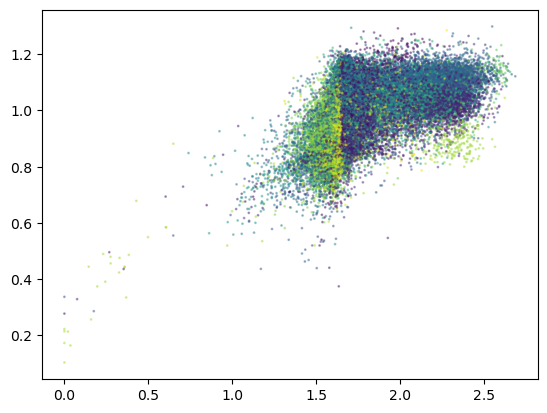

In [8]:
fig, ax = plt.subplots()

sc=plt.scatter(df[0], df[1], c=kmeans.labels_.astype(float), s=1, alpha=0.4, cmap='viridis') # 

# plt.scatter(centroids[:, 0], centroids[:, 3], c='red', s=30)
# ax.legend(*sc.legend_elements(), loc="lower left", title="Classes")
plt.show()

### Clusters

In [21]:
from scipy.cluster.vq import kmeans,vq

# assign each sample to a cluster
idx,_ = vq(df,centroids)

#Print number of elements per cluster
print(np.bincount(idx))

[   4  284   34  282 4584 3587   71  477   74 1204 1188  271  135 2898
  366   95  221   12  265   84   83  290  103  359  187   96   21 2024
  126 2901  128 2849   95  117  523   18 5488   93  292  191  588  313
  132   92   48  311  130  158  999   97  319  117   52  158  992   21
   26  115   70 1766   22  537  623  797  112  418  191  148    0   20
    0  126   82   14  137   31   82   73  169  121 4441  230   51  299
  269  297   74   82  141   91   22 2278   15  434   42   82  689   99
  622   41]


In [22]:
df_clusters = pd.DataFrame()
df_clusters['filenames']= embeds.keys()

In [23]:
df_clusters['cluster']=idx

In [24]:
df_clusters['labels']=labels

In [25]:
df_clusters

,filenames,cluster,labels
0,pc_0_RIBERA_pt436662_w2119,4,3
1,pc_0_CAT3_493679_w1641,80,3
2,pc_0_RIBERA_pt440652_w248,36,3
3,pc_0_RIBERA_pt436656_w963,54,3
4,pc_0_CAT3_508699_w1191,5,3
...,...,...,...
52621,pc_0_RIBERA_pt436656_w5333,36,3
52622,pc_0_RIBERA_pt436656_w1393,29,3
52623,pc_0_RIBERA_pt436656_w5303,36,3
52624,pc_0_RIBERA_pt436662_w3686,84,3


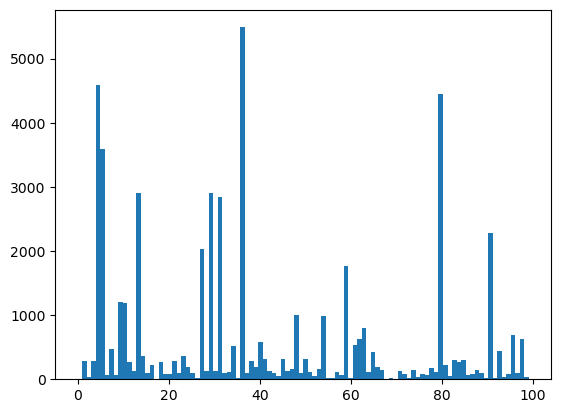

In [26]:
sc=plt.hist(df_clusters['cluster'], bins=100)


In [27]:
clusters_count = df_clusters.groupby(['cluster']).count()
clusters_count

,filenames,labels
cluster,,
0,4,4
1,284,284
2,34,34
3,282,282
4,4584,4584
...,...,...
95,82,82
96,689,689
97,99,99


In [28]:
embeddings = df.to_numpy()

In [29]:
embeddings.shape

(52626, 1024)

In [30]:
cluster_ids=idx
cluster_ids.shape

(52626,)

In [31]:
centroids.shape

(100, 1024)

In [38]:
from sklearn.metrics.pairwise import cosine_similarity
threshold=0.996
embeds_less_similar=[]
embeds_filenames=[]
all_similarities=[]

# Loop through each cluster
for i in tqdm(range(100)):
    # Get the indices of the embeddings in the current cluster
    indices = np.where(cluster_ids == i)[0]
    # get embeddings of cluster
    cluster_embeddings = embeddings[indices]
    cluster_filenames = df_clusters['filenames'][indices].to_list()
    
    # Compute the pairwise cosine similarities between the embeddings in the current cluster and the cluster centroid
    centroid = centroids[i]
    similarities=[]
    
    for embedding in cluster_embeddings:
        sim=cosine_similarity(embedding.reshape(1, -1), centroid.reshape(1, -1)).item()
        similarities.append(sim)
        all_similarities.append(sim)
    # Identify the embeddings in the current cluster that are less similar to the centroid (above threshold)
#     max_similarity_index = np.argmax(similarities)
#     max_similarity_embedding = cluster_embeddings[max_similarity_index]
    # Keep only the embeddings with similarities below the threshold
    for j in range(len(similarities)):
        if similarities[ j] < threshold or j==0:
            
            embeds_less_similar.append(cluster_embeddings[j]) #less_similar
            embeds_filenames.append(cluster_filenames[j]) # keep_embeds
    
    

  0%|          | 0/100 [00:00<?, ?it/s]

In [39]:
len(embeds_filenames)

20513

In [60]:
final_list=[]
embeds_left=embeds_less_similar

for j in tqdm(range(len(embeds_less_similar))):
    similar=False
    
    for k in range(len(embeds_left)):
        
        embed_1 = embeds_less_similar[j].reshape(1, -1)
        embed_2 = embeds_left[k].reshape(1, -1)
        sim=cosine_similarity(embed_1, embed_2).item()
        
        if 1>sim >= threshold and (embeds_less_similar[j] != embeds_left[k]).all():
            similar=True
            break
            
    embeds_left = embeds_less_similar[j+1:]
    
    if not similar:
        final_list.append(embeds_filenames[j])
#         print(final_list)
        
    

  0%|          | 0/20513 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
len(final_list)

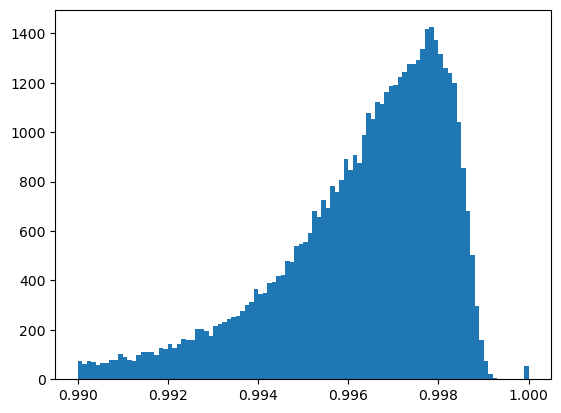

In [83]:
h=plt.hist(all_similarities,bins=100,log=False,range=[0.99, 1],)

In [51]:
len(embeds_filenames)

20513

In [53]:
len([i for i in embeds_filenames if 'tower'in i])

766

In [54]:
len([i for i in df.index if 'tower'in i])

1084

In [81]:
# with open("train_reduced_files_semdedup0996.txt", "w") as file:

#     for f in embeds_filenames:
#         file.write(f + ".pt\n")

In [92]:
with open("train_reduced_files_semdedup0996.txt", "r") as file:
    train_files = file.read().splitlines()

In [93]:
len(train_files)

20513

In [94]:
len([i for i in train_files if 'tower'in i])

766

In [115]:
with open("/home/m.caros/work/objectDetection/train_test_files/RGBN_40x40_barlow_50/train_cls_files.txt", "r") as file:
    train_files = file.read().splitlines()
    
len(train_files)

26313